In [ ]:
import numpy as np
import pandas as pd
import os

import seaborn as sns
import matplotlib.pyplot as plt
import gudhi as gd
from laplacians import compute_boundary_matrices, gudhi_to_dio

In [ ]:
def point_set_to_params(point_set, seed):
    if point_set in ["unif3D", "unif100D"]:
        filtration = "rips"
        if point_set == "unif100D":
            max_t = 5.0
            seed += 3000
        else:
            max_t = 0.3
            seed += 1000
    elif point_set in ["unif2D", "sphere3D"]:
        filtration = "alpha"
        if point_set == "unif2D":
            seed += 0
            max_t = None
        else:
            seed += 2000
            max_t = None
    return filtration, max_t, seed

def plot_timings(point_sets, seeds=0, methods=["new_chains", "petls", "petls_combined", "pinv"], x_plot="n_points", log_scale_y=True, log_scale_x=False, plot_y_power=(False, 4), fit_fraction=0.5, fit_log=True, ax=None, legend=True):
    if type(point_sets) == str:
        point_sets = [point_sets]
    if type(seeds) == int:
        seeds = [seeds]

    method_names = {
        "new_chains": "New Chains",
        "petls": "PETLS",
        "petls_combined": "PETLS (Relevant Locations)",
        "pinv": "Schur Complement"
    }

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    for method in methods:
        df_combined = None
        for point_set in point_sets:
            for seed in seeds:
                filtration, max_t, seed = point_set_to_params(point_set, seed)
                if filtration == "rips":
                    csv_file = f"{point_set}_{seed}_t={max_t}.csv"
                elif filtration == "alpha":
                    csv_file = f"{point_set}_{seed}.csv"
                df = pd.read_csv(f"results/timings/{filtration}/{method}/{csv_file}", index_col="n_points")
                if x_plot == "n_simplices" or x_plot == "n_timesteps":
                    all_points = np.loadtxt(f"point_sets/{point_set}/seed={seed}.csv", delimiter=",")
                    x_axis = []
                    for n in df.index:
                        random_points = all_points[:n]
                        if filtration == "rips":
                            st = gd.RipsComplex(points=random_points, max_edge_length=max_t).create_simplex_tree(max_dimension=4)
                        elif filtration == "alpha":
                            st = gd.AlphaComplex(points=random_points).create_simplex_tree()
                        if x_plot == "n_timesteps":
                            boundary_matrices, simplices_at_time, relevant_times = compute_boundary_matrices(gudhi_to_dio(st))
                            x_axis.append(len(relevant_times))
                        elif x_plot == "n_simplices":
                            x_axis.append(st.num_simplices())
                    df["n_simplices"] = x_axis
                    df = df.set_index("n_simplices", drop=True)
                df.rename(columns={i: f"{point_set}_{seed}_{i}" for i in df.columns}, inplace=True)
                if df_combined is None:
                    df_combined = df
                else:
                    df_combined = pd.merge(df_combined, df, left_index=True, right_index=True, how="outer")
        # print(df_combined)
        test = df_combined.apply(lambda row: list(row), result_type="reduce", axis=1).explode()

        sns.lineplot(x = test.index, y = test.values, label=method_names.get(method, method), ax=ax)

        if plot_y_power[0]:
            # Fit y = c*x^p for fixed p by least squares, using only the last fit_fraction of the x-values.
            # fit_log=True: in log space, log(c) = mean(log(y) - p*log(x)), weighing each point equally
            # fit_log=False: in linear space, c = sum(y*x^p) / sum(x^(2p))
            color = ax.get_lines()[-1].get_color()
            p = plot_y_power[1]
            x_data = test.index.to_numpy(dtype=float)
            y_data = pd.to_numeric(test, errors="coerce").to_numpy(dtype=float)
            x_data, y_data = x_data[~np.isnan(y_data)], y_data[~np.isnan(y_data)]
            x_cutoff = x_data[int(len(x_data) * (1 - fit_fraction))]
            fit_mask = x_data >= x_cutoff
            if fit_log:
                c = np.exp(np.mean(np.log(y_data[fit_mask]) - p * np.log(x_data[fit_mask])))
            else:
                x_p = np.power(x_data[fit_mask], p)
                c = np.sum(y_data[fit_mask] * x_p) / np.sum(x_p**2)
            print(f"{method_names.get(method, method)}: y = {c:.3e} * x^{p}")
            x_fit = np.linspace(x_data.min(), x_data.max(), 1000)
            ax.plot(x_fit, c * np.power(x_fit, p), linestyle="--", color=color)

    if plot_y_power[0]:
        ax.plot([], [], linestyle="--", color="gray", label=f"Best fit t=c·x^{plot_y_power[1]}")
    
    if x_plot == "n_simplices":
        ax.set_xlabel("Number of simplices")
    elif x_plot == "n_points":
        ax.set_xlabel("Number of points")
    elif x_plot == "n_timesteps":
        ax.set_xlabel("Number of timesteps")

    ax.set_ylabel("Time (seconds)")

    if point_set.startswith("sphere3D"):
        ax.set_title(f"3D unit sphere with {filtration} filtration")
    elif point_set.startswith("unif3D"):
        ax.set_title(f"3D unit cube with {filtration} filtration")
    elif point_set.startswith("unif2D"):
        ax.set_title(f"2D unit square with {filtration} filtration")
    elif point_set.startswith("unif100D"):
        ax.set_title(f"100D unit cube with {filtration} filtration")

    if log_scale_y:
        ax.set_yscale("log")
    if log_scale_x:
        ax.set_xscale("log")
    if legend:
        ax.legend(loc="upper left")
    else:
        ax.get_legend().remove()

New Chains: y = 1.507e-08 * x^3
PETLS (Relevant Locations): y = 1.361e-08 * x^3
PETLS: y = 6.744e-08 * x^3
Schur Complement: y = 2.293e-07 * x^3


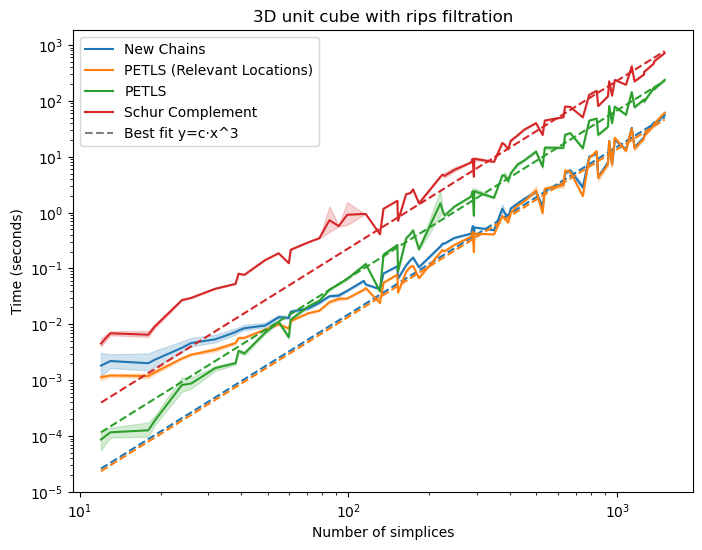

In [ ]:
methods = ["new_chains", "petls_combined", "petls", "pinv"]
point_set = ["unif3D"]

x_plot = "n_simplices" # or "n_points"

plot_timings(point_set, seeds=[0, 1, 2, 3], methods=methods, x_plot=x_plot, log_scale_y=True, log_scale_x=True, plot_y_power=(True, 3), fit_log=True)

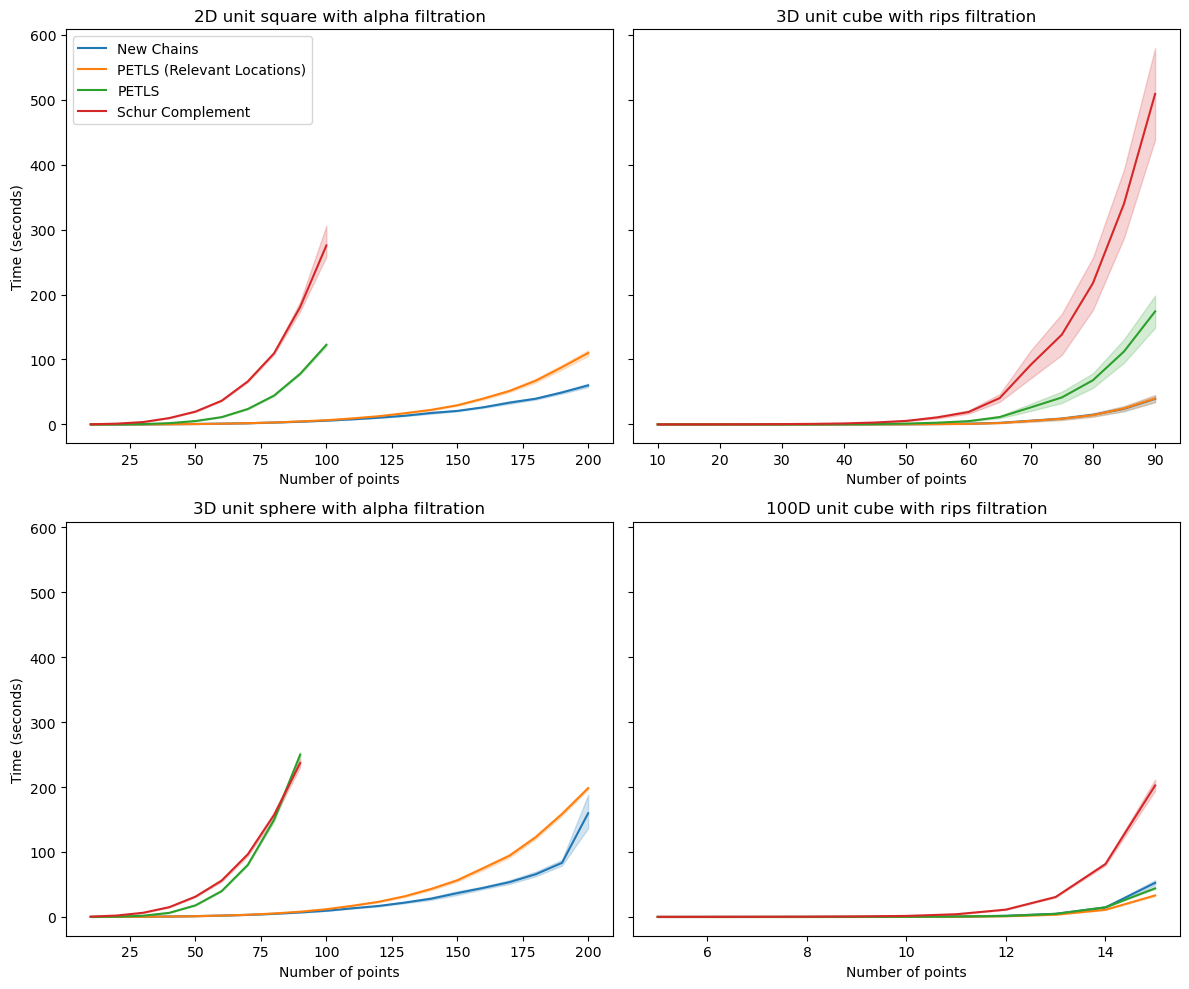

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10), sharex=False, sharey=True)

x_plot = "n_points" # or "n_points"
log_scale_y = False
log_scale_x = False
fit_fraction = 1
plot_y_power = (False, 3)
seeds = [0, 1, 2, 3, 4]
fit_log = False

plot_timings("unif2D", seeds=seeds, methods=methods, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x, plot_y_power=plot_y_power, ax=ax[0][0], legend=True, fit_fraction=fit_fraction, fit_log=fit_log)
plot_timings("unif3D", seeds=seeds, methods=methods, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x, plot_y_power=plot_y_power, ax=ax[0][1], legend=False, fit_fraction=fit_fraction, fit_log=fit_log)
plot_timings("sphere3D", seeds=seeds, methods=methods, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x, plot_y_power=plot_y_power, ax=ax[1][0], legend=False, fit_fraction=fit_fraction, fit_log=fit_log)
plot_timings("unif100D", seeds=seeds, methods=methods, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x, plot_y_power=plot_y_power, ax=ax[1][1], legend=False, fit_fraction=fit_fraction, fit_log=fit_log)
plt.tight_layout()
# plt.savefig("results/figures/timings_all_point_sets.pdf")

New Chains: y = 3.546e-08 * x^3
PETLS (Relevant Locations): y = 5.975e-08 * x^3
PETLS: y = 5.963e-07 * x^3
Schur Complement: y = 1.387e-06 * x^3
New Chains: y = 1.168e-08 * x^3
PETLS (Relevant Locations): y = 1.182e-08 * x^3
PETLS: y = 5.412e-08 * x^3
Schur Complement: y = 1.660e-07 * x^3
New Chains: y = 3.929e-09 * x^3
PETLS (Relevant Locations): y = 6.061e-09 * x^3
PETLS: y = 9.880e-08 * x^3
Schur Complement: y = 1.004e-07 * x^3
New Chains: y = 4.241e-10 * x^3
PETLS (Relevant Locations): y = 2.724e-10 * x^3
PETLS: y = 3.626e-10 * x^3
Schur Complement: y = 1.720e-09 * x^3


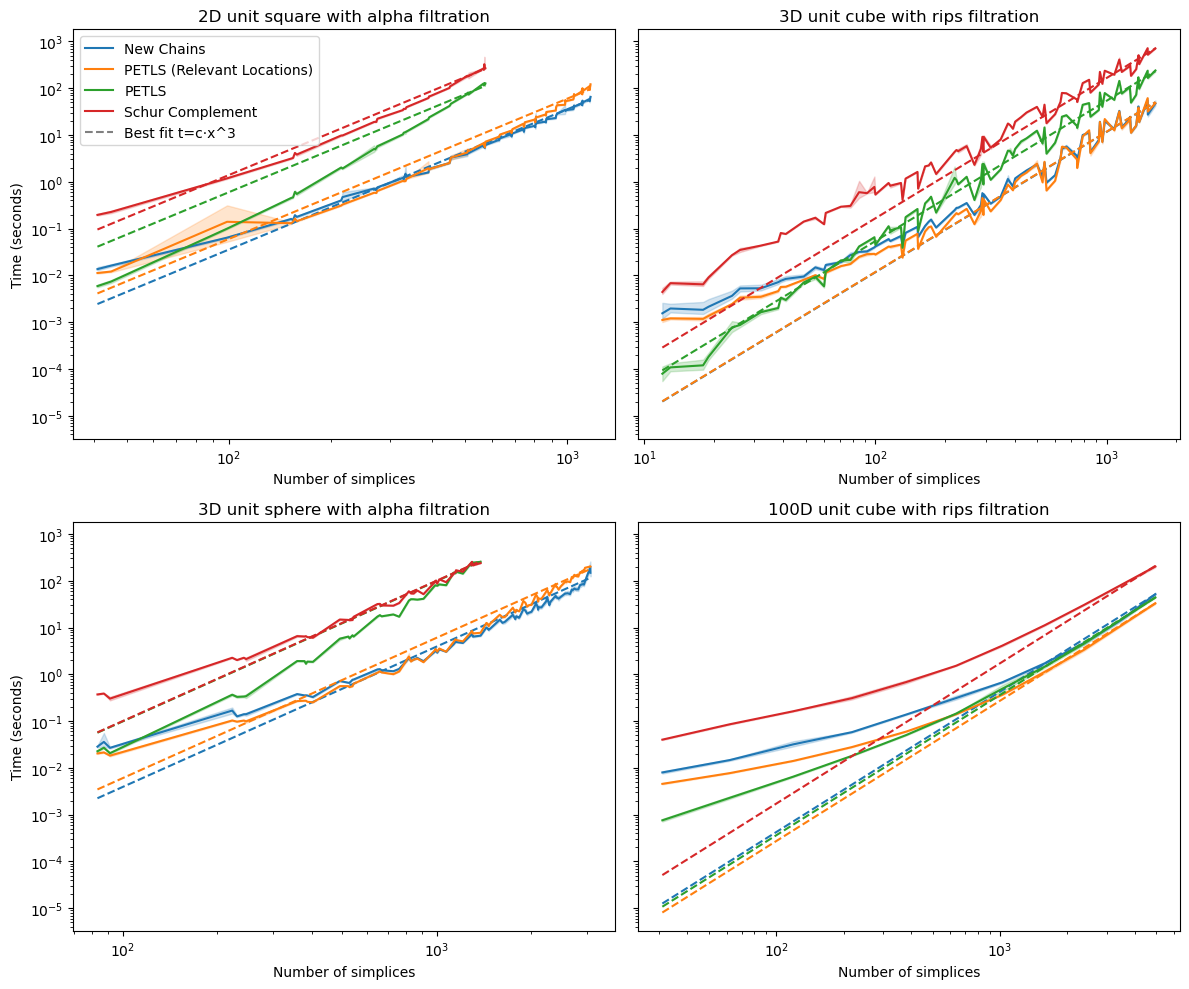

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10), sharex=False, sharey=True)

x_plot = "n_simplices" # or "n_points"
log_scale_y = True
log_scale_x = True
fit_fraction = 1
plot_y_power = (True, 3)
fit_log = False
seeds = [0, 1, 2, 3, 4]

plot_timings("unif2D", seeds=seeds, methods=methods, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x, plot_y_power=plot_y_power, ax=ax[0][0], legend=True, fit_fraction=fit_fraction, fit_log=fit_log)
plot_timings("unif3D", seeds=seeds, methods=methods, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x, plot_y_power=plot_y_power, ax=ax[0][1], legend=False, fit_fraction=fit_fraction, fit_log=fit_log)
plot_timings("sphere3D", seeds=seeds, methods=methods, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x, plot_y_power=plot_y_power, ax=ax[1][0], legend=False, fit_fraction=fit_fraction, fit_log=fit_log)
plot_timings("unif100D", seeds=seeds, methods=methods, x_plot=x_plot, log_scale_y=log_scale_y, log_scale_x=log_scale_x, plot_y_power=plot_y_power, ax=ax[1][1], legend=False, fit_fraction=fit_fraction, fit_log=fit_log)
plt.tight_layout()
plt.savefig("results/figures/timings_all_point_sets_n_simplices.pdf")